<a href="https://www.kaggle.com/code/gowthamsevathan/spaceship-titanic?scriptVersionId=365508452" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

### Problem Statement:  task is to predict whether a passenger was transported to an alternate dimension during the Spaceship Titanic's collision with the spacetime anomaly

```train.csv - Personal records for about two-thirds (~8700) of the passengers, to be used as training data.```

contained Columns : ```1. PassengerId``` 2. ```HomePlanet ``` 3.```CryoSleep``` 4. ```Cabin``` 5. ```Destination ```6. ```Age``` 7. ```VIP``` 8.```RoomService, FoodCourt, ShoppingMall, Spa, VRDeck ``` .etc

### Instrection to Followed:
1. Require Library
2. Inspection the data


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load
import matplotlib.pyplot as plt
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/spaceship-titanic/sample_submission.csv
/kaggle/input/competitions/spaceship-titanic/train.csv
/kaggle/input/competitions/spaceship-titanic/test.csv


# 1. Require Library

In [2]:
#Import the library which we needed 
import pandas as pd 
import numpy as np

the data which contain 14 columns and each of them have different info we use ```df = data_frame ``` it will hold the all the record.

In [3]:
df = pd. read_csv('/kaggle/input/competitions/spaceship-titanic/train.csv')

In [4]:
df.sample(100)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
7567,8088_01,Mars,False,E/521/P,TRAPPIST-1e,23.0,False,1.0,0.0,11.0,0.0,2336.0,Ducks Sacy,False
6729,7097_01,Europa,False,A/75/P,55 Cancri e,27.0,False,0.0,44.0,4761.0,5.0,41.0,Altanin Dedometeel,True
4557,4848_01,Earth,False,F/986/P,TRAPPIST-1e,30.0,False,148.0,0.0,0.0,619.0,34.0,Nathy Griffince,True
4884,5207_01,Earth,False,E/331/S,55 Cancri e,18.0,False,51.0,339.0,1.0,0.0,436.0,Bonyan Chanan,True
2730,2928_03,Europa,True,B/92/P,TRAPPIST-1e,44.0,False,0.0,0.0,0.0,0.0,0.0,Gluinol Mander,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6719,7089_01,Europa,False,D/218/S,TRAPPIST-1e,20.0,False,1040.0,2487.0,0.0,174.0,182.0,Antinon Inging,True
3041,3287_03,Earth,False,F/621/S,55 Cancri e,18.0,False,0.0,NaN,14.0,625.0,0.0,Therie Carlsonney,False
4319,4603_02,Europa,False,C/171/S,TRAPPIST-1e,36.0,False,1.0,5234.0,343.0,277.0,12682.0,Kabih Namsheary,False
1736,1849_01,Earth,False,F/367/P,TRAPPIST-1e,25.0,False,113.0,0.0,0.0,1282.0,0.0,Antone Sellentry,False


check shape of the data.

In [5]:
print(f'column :{df.shape[1]} , row : {df.shape[0]}')

column :14 , row : 8693


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB
None


In [7]:
print(df.dtypes.value_counts())

object     7
float64    6
bool       1
Name: count, dtype: int64


the data type for each columns : 
```e
object is : 7
float : 6
bool : 1 
will see is there any way that e can change the float into int

### 2) Check the missing values

1. it's importent have a look because it can make big diferent in model building.

In [8]:
def null_value(data):
    missing_count = data.isnull().sum()
    missing_per = missing_count / len(data)*100
    result = pd.DataFrame({'Missing_count':missing_count , 'Missing%':missing_per})
    return result[result['Missing_count']>0].sort_values(by='Missing_count', ascending=False)

In [9]:
null_value(df)

,Missing_count,Missing%
CryoSleep,217,2.496261
ShoppingMall,208,2.392730
VIP,203,2.335212
HomePlanet,201,2.312205
Name,200,2.300702
Cabin,199,2.289198
VRDeck,188,2.162660
FoodCourt,183,2.105142
Spa,183,2.105142
Destination,182,2.093639


In [10]:
df.shape[1]

14

In [11]:
print(df['Transported'].value_counts(normalize=True))

Transported
True     0.503624
False    0.496376
Name: proportion, dtype: float64


two group are almost equel **above 50% of passengers transported  and 49.6% passengers not transported** 

In [12]:
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


splitthe passengerID into two part one is a **> group** and **member** 

In [13]:
df['Group'] = df['PassengerId'].str.split('_').str[0]
df['Member'] = df['PassengerId'].str.split('_').str[1]

In [14]:
df[['PassengerId','Group','Member']].head()

,PassengerId,Group,Member
0,0001_01,0001,01
1,0002_01,0002,01
2,0003_01,0003,01
3,0003_02,0003,02
4,0004_01,0004,01


In [15]:
df['Group_Size'] = df.groupby('Group')['PassengerId'].transform('count')

Count each Group, like to count to know, how many prople has travel to them or grop of people 

In [16]:
df[['PassengerId','Group_Size']].head()

,PassengerId,Group_Size
0,0001_01,1
1,0002_01,1
2,0003_01,2
3,0003_02,2
4,0004_01,1


we can see there,
in the cabin wil have 3 different type of info ```B/0/P``` B = Bench , 0 = cabin number P = Port whic mean which side of the flight. 

will seperate them into three different column one ```Desk``` , ```Cabin_num``` and ```Side``` so maodel can understand better 

In [17]:
df['Deck'] = df['Cabin'].str.split('/').str[0]
df['Cabin_num'] = df['Cabin'].str.split('/').str[1]
df['Side'] = df['Cabin'].str.split('/').str[2]

In [18]:
df[['Deck','Cabin_num','Side']].head()

,Deck,Cabin_num,Side
0,B,0,P
1,F,0,S
2,A,0,S
3,A,0,S
4,F,1,S


``` Total_spend_by Customer``` which can give more information like what is therange of money they spended to geot more hidden thing's.

In [19]:
df['Total_spend'] = df[['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']].sum(axis=1)

In [20]:
df[['PassengerId','Total_spend']].head()

,PassengerId,Total_spend
0,0001_01,0.0
1,0002_01,736.0
2,0003_01,10383.0
3,0003_02,5176.0
4,0004_01,1091.0


In [21]:
df['Spa']

0          0.0
1        549.0
2       6715.0
3       3329.0
4        565.0
         ...  
8688    1643.0
8689       0.0
8690       1.0
8691     353.0
8692       0.0
Name: Spa, Length: 8693, dtype: float64

In [22]:
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,VRDeck,Name,Transported,Group,Member,Group_Size,Deck,Cabin_num,Side,Total_spend
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,...,0.0,Maham Ofracculy,False,0001,01,1,B,0,P,0.0
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,...,44.0,Juanna Vines,True,0002,01,1,F,0,S,736.0
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,...,49.0,Altark Susent,False,0003,01,2,A,0,S,10383.0
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,...,193.0,Solam Susent,False,0003,02,2,A,0,S,5176.0
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,...,2.0,Willy Santantines,True,0004,01,1,F,1,S,1091.0


Someone asleep in their cabin can’t use the spa or the food court, so I expect Total_spend to be about 0 for CryoSleep = True and above 0 for CryoSleep = False.

In [23]:
df.groupby('CryoSleep')['Total_spend'].mean().round(2)

CryoSleep
False    2248.3
True        0.0
Name: Total_spend, dtype: float64

### Does CryoSleep affect being transported?
Because sleeping passengers stayed locked in their cabins the whole trip, I expect the Transported rate to be different for CryoSleep = True than for CryoSleep = False.

In [24]:
df.groupby('CryoSleep')['Transported'].mean().round(2)*100

CryoSleep
False    33.0
True     82.0
Name: Transported, dtype: float64

in this case awake passengers transporde 33% and and sleeper 82%/100 

# 10: Does the home planet matter?
Because passengers from different planets may have different lives and habits on board, I expect the transported share to be different for different HomePlanet groups.

In [25]:
df.groupby('HomePlanet')['Transported'].mean().round(2)*100

HomePlanet
Earth     42.0
Europa    66.0
Mars      52.0
Name: Transported, dtype: float64

we can see that the passenger has been transported some of them and some of them not but we can see that differeent clearly 
*  Earth     42.0
* Europa    66.0
* Mars      52.0

# 11: Does the deck matter?
Because the ship’s decks are different parts of the ship, and the anomaly may have hit some parts harder, I expect the transported share to differ by Deck.

In [26]:
df.groupby('Deck')['Transported'].mean().round(2)*100

Deck
A    50.0
B    73.0
C    68.0
D    43.0
E    36.0
F    44.0
G    52.0
T    20.0
Name: Transported, dtype: float64

* Deck B: 73 out of every 100 were transported (highest).
* Deck C: 68 out of every 100.
* Deck A: 50 out of every 100.
* Deck E: 36 out of every 100 (lowest among the big decks)1. 

## 12: Check the deck sizes


In [27]:
df['Deck'].value_counts()

Deck
F    2794
G    2559
E     876
B     779
C     747
D     478
A     256
T       5
Name: count, dtype: int64

## 13: Does the side matter?
The ship has two sides, Port (P) and Starboard (S). Because a spacetime anomaly could hit one side harder, I expect the transported share to differ by Side. But with only two groups, I think the gap will be small.

In [28]:
df.groupby('Side')['Transported'].mean().round(2)*100

Side
P    45.0
S    56.0
Name: Transported, dtype: float64

we ca nsee the different of each side and ```Port``` sid has Transported 45% and ``` Starboard``` 56% there will be chance's of hid in one sind is most or has window in othere side P - S different from each 9 it showing huge impact too.

In [29]:
df['Side'].value_counts()

Side
S    4288
P    4206
Name: count, dtype: int64

## 14: Does age matter?
Because children travelling with family might have been treated differently from adults, I expect the transported share to be higher for young children than for adults.

In [30]:
df['age_band'] = pd.cut(df['Age'], bins=[0, 12, 18, 30, 50, 100])


In [31]:
df.groupby('age_band')['Transported'].mean()

/tmp/ipykernel_16/1129482245.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_band')['Transported'].mean()


age_band
(0, 12]      0.668790
(12, 18]     0.537299
(18, 30]     0.468190
(30, 50]     0.479432
(50, 100]    0.484396
Name: Transported, dtype: float64

In [32]:
df['age_band'].value_counts()

age_band
(18, 30]     3238
(30, 50]     2674
(12, 18]     1059
(50, 100]     737
(0, 12]       628
Name: count, dtype: int64

In [33]:
df[df['Age'] == 0]['Transported'].mean()

np.float64(0.8089887640449438)

In [34]:
df['age_band'].value_counts()

age_band
(18, 30]     3238
(30, 50]     2674
(12, 18]     1059
(50, 100]     737
(0, 12]       628
Name: count, dtype: int64

In [35]:
df['age_band'] = pd.cut(df['Age'], bins=[0, 12, 18, 30, 50, 100], include_lowest=True)

In [36]:
df['age_band']

0        (30.0, 50.0]
1        (18.0, 30.0]
2       (50.0, 100.0]
3        (30.0, 50.0]
4        (12.0, 18.0]
            ...      
8688     (30.0, 50.0]
8689     (12.0, 18.0]
8690     (18.0, 30.0]
8691     (30.0, 50.0]
8692     (30.0, 50.0]
Name: age_band, Length: 8693, dtype: category
Categories (5, interval[float64, right]): [(-0.001, 12.0] < (12.0, 18.0] < (18.0, 30.0] < (30.0, 50.0] < (50.0, 100.0]]

In [37]:
df[df['Age'] == 0].shape[0]

178

In [38]:
df.groupby('age_band')['Transported'].mean() * 100

/tmp/ipykernel_16/2759079635.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_band')['Transported'].mean() * 100


age_band
(-0.001, 12.0]    69.975186
(12.0, 18.0]      53.729934
(18.0, 30.0]      46.819024
(30.0, 50.0]      47.943156
(50.0, 100.0]     48.439620
Name: Transported, dtype: float64

## 17: Does spending nothing matter?
Because every CryoSleep passenger spent 0, I expect passengers with Total_spend of 0 to be transported more often than passengers who spent something. Some awake passengers also spent 0, so I expect the gap to be smaller than CryoSleep’s 49 points.

In [39]:
df['no_spend'] = df['Total_spend'] == 0
df.groupby('no_spend')['Transported'].mean()


no_spend
False    0.298611
True     0.786477
Name: Transported, dtype: float64

In [40]:
df['no_spend'].value_counts()

no_spend
False    5040
True     3653
Name: count, dtype: int64

## 18: Test my guess about CryoSleep


In [41]:
df.groupby(['CryoSleep', 'no_spend'])['Transported'].mean() * 100

CryoSleep  no_spend
False      False       29.871977
           True        61.583012
True       True        81.758314
Name: Transported, dtype: float64

In [42]:
df.groupby(['CryoSleep', 'no_spend']).size()

CryoSleep  no_spend
False      False       4921
           True         518
True       True        3037
dtype: int64

## 19: Does group size matter?
: I’m not sure which direction it goes. People travelling alone might behave differently from people in a group, so I expect the transported share to differ by Group_Size.

In [43]:
df.groupby('Group_Size')['Transported'].mean() * 100

Group_Size
1    45.244537
2    53.804994
3    59.313725
4    64.077670
5    59.245283
6    61.494253
7    54.112554
8    39.423077
Name: Transported, dtype: float64

In [44]:
df['Group_Size'].value_counts().sort_index()

Group_Size
1    4805
2    1682
3    1020
4     412
5     265
6     174
7     231
8     104
Name: count, dtype: int64

## 20: Create the solo clue
group sizes bounce around from 1 to 8, but one split is clean. Is this passenger travelling alone, yes or no? We’ll make that yes/no column, the same way we made no_spend, and test it.

In [45]:
df['is_solo'] = df['Group_Size'] == 1

In [46]:
df['is_solo'].value_counts()

is_solo
True     4805
False    3888
Name: count, dtype: int64

In [47]:
df.groupby('is_solo')['Transported'].mean() * 100

is_solo
False    56.687243
True     45.244537
Name: Transported, dtype: float64

## 21 Use the CryoSleep rule to fill blanks
we learned that a sleeping passenger always spends 0. So if a sleeper has a blank in RoomService, we don’t have to guess: the blank must be 0. It’s like a patient asleep under anaesthesia whose cafeteria bill has a smudged line. The smudged line can only be zero.

In [48]:
df[(df['CryoSleep'] == True) & (df['RoomService'].isnull())].shape[0]

68

## 22: Fill those 68 blanks with 0
we write 0 into exactly those 68 cells and leave every other blank alone. We do one column first and check that it worked before repeating it for the other four.

In [49]:
df.loc[(df['CryoSleep'] == True) & (df['RoomService'].isnull()), 'RoomService'] = 0

In [50]:
df['RoomService'].isnull().sum()

np.int64(113)

## 23: Repeat for the other four spending columns
the same rule applies to FoodCourt, ShoppingMall, Spa and VRDeck: a sleeper’s blank must be 0. Instead of writing the same line four times, we put the column names in a list and repeat the line for each one. It’s like stamping the same fix on four forms.

In [51]:
df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].isnull().sum()

RoomService     113
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
dtype: int64

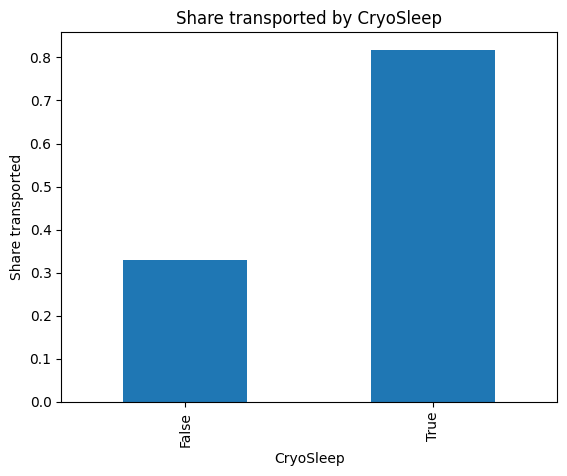

In [52]:
df.groupby('CryoSleep')['Transported'].mean().plot(kind='bar')
plt.title('Share transported by CryoSleep')
plt.ylabel('Share transported')
plt.show()

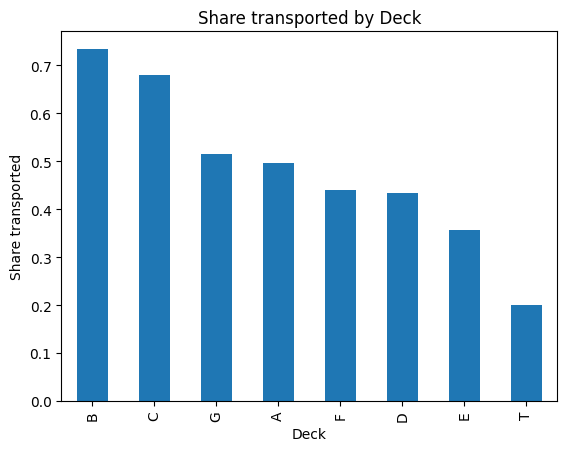

In [53]:
df.groupby('Deck')['Transported'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Share transported by Deck')
plt.ylabel('Share transported')
plt.show()

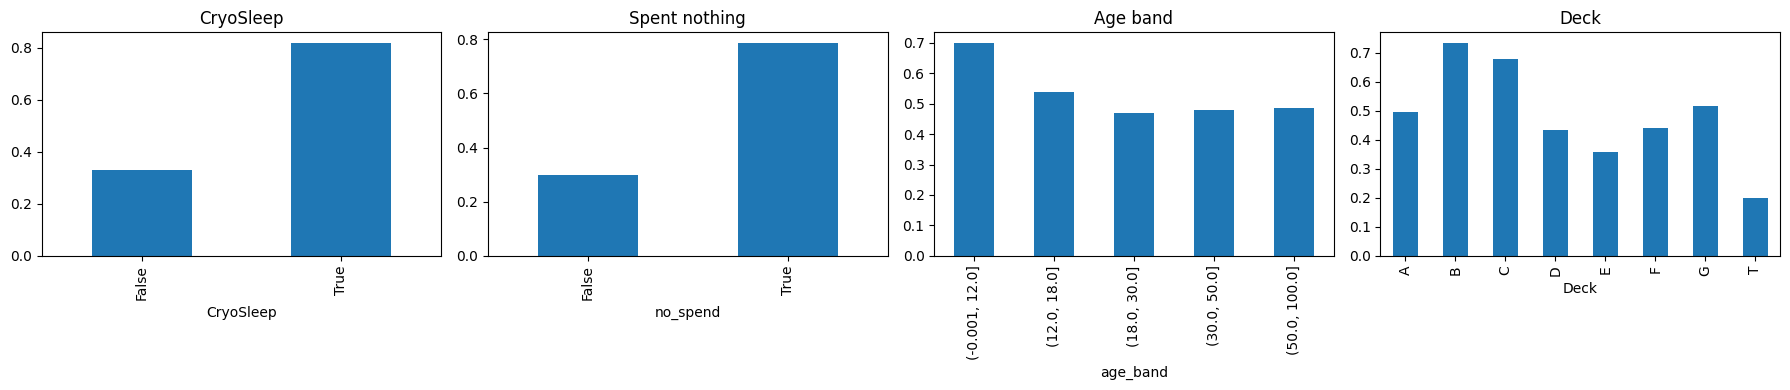

In [54]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))

df.groupby('CryoSleep')['Transported'].mean().plot(kind='bar', ax=ax[0], title='CryoSleep')
df.groupby('no_spend')['Transported'].mean().plot(kind='bar', ax=ax[1], title='Spent nothing')
df.groupby('age_band', observed=True)['Transported'].mean().plot(kind='bar', ax=ax[2], title='Age band')
df.groupby('Deck')['Transported'].mean().plot(kind='bar', ax=ax[3], title='Deck')

plt.tight_layout()
plt.show()

In [55]:
spend_cols = ['FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

for col in spend_cols:
    df.loc[(df['CryoSleep'] == True) & (df[col].isnull()), col] = 0

print(df[['RoomService'] + spend_cols].isnull().sum())

RoomService     113
FoodCourt       113
ShoppingMall    112
Spa             118
VRDeck          126
dtype: int64


In [56]:
num_cols = ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

cat_cols = ['HomePlanet', 'CryoSleep', 'VIP', 'Destination', 'Deck', 'Side']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

PassengerId       0
HomePlanet        0
CryoSleep         0
Cabin           199
Destination       0
Age               0
VIP               0
RoomService       0
FoodCourt         0
ShoppingMall      0
Spa               0
VRDeck            0
Name            200
Transported       0
Group             0
Member            0
Group_Size        0
Deck              0
Cabin_num       199
Side              0
Total_spend       0
age_band        179
no_spend          0
is_solo           0
dtype: int64


/tmp/ipykernel_16/53671497.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(df[col].mode()[0])


In [57]:
spend = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
df['Total_spend'] = df[spend].sum(axis=1)
df['no_spend'] = df['Total_spend'] == 0

features = ['HomePlanet', 'CryoSleep', 'VIP', 'Destination', 'Deck', 'Side', 'Age'] \
           + spend + ['Total_spend', 'no_spend', 'Group_Size', 'is_solo']
X = df[features].copy()

for c in ['CryoSleep', 'VIP', 'no_spend', 'is_solo']:
    X[c] = X[c].astype(bool).astype(int)
X = pd.get_dummies(X, columns=['HomePlanet', 'Destination', 'Deck', 'Side'])
y = df['Transported'].astype(int)


X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

print('Accuracy:', round(accuracy_score(y_val, model.predict(X_val)), 3))
print('Baseline:', round(max(y_val.mean(), 1 - y_val.mean()), 3))

Accuracy: 0.795
Baseline: 0.504


In [58]:
test = pd.read_csv('/kaggle/input/competitions/spaceship-titanic/test.csv')   # download test.csv from the Kaggle data page

def prepare(d):
    d = d.copy()
    d['Group'] = d['PassengerId'].str.split('_').str[0]
    d['Group_Size'] = d.groupby('Group')['PassengerId'].transform('count')
    d['is_solo'] = d['Group_Size'] == 1
    d['Deck'] = d['Cabin'].str.split('/').str[0]
    d['Side'] = d['Cabin'].str.split('/').str[2]

    for col in spend:                      # sleeper rule
        d.loc[(d['CryoSleep'] == True) & d[col].isnull(), col] = 0
    for col in ['Age'] + spend:            # fill with TRAIN medians
        d[col] = d[col].fillna(df[col].median())
    for col in ['HomePlanet', 'CryoSleep', 'VIP', 'Destination', 'Deck', 'Side']:
        d[col] = d[col].fillna(df[col].mode()[0])   # TRAIN most-common values

    d['Total_spend'] = d[spend].sum(axis=1)
    d['no_spend'] = d['Total_spend'] == 0
    return d

T = prepare(test)
X_test = T[features].copy()
for c in ['CryoSleep', 'VIP', 'no_spend', 'is_solo']:
    X_test[c] = X_test[c].astype(bool).astype(int)
X_test = pd.get_dummies(X_test, columns=['HomePlanet', 'Destination', 'Deck', 'Side'])
X_test = X_test.reindex(columns=X.columns, fill_value=0)   # same columns, same order

model.fit(X, y)                            # retrain on ALL training rows
preds = model.predict(X_test).astype(bool)

submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Transported': preds})
submission.to_csv('submission.csv', index=False)
print(submission.shape)
print(submission.head())

/tmp/ipykernel_16/872023628.py:16: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d[col] = d[col].fillna(df[col].mode()[0])   # TRAIN most-common values


(4277, 2)
  PassengerId  Transported
0     0013_01         True
1     0018_01        False
2     0019_01         True
3     0021_01         True
4     0023_01         True
